# EDA & Preprocessing Rationale
Fraud detection on the **Elliptic Bitcoin** graph (203,769 transactions, 234,355 edges).

This notebook answers:
1. What does the data look like?
2. Why do we build graph features?
3. Why do we use specific transforms (log, robust, quantile, power, scaling)?
4. Why temporal split + cost-based evaluation?


In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')
pd.set_option('display.max_columns', 200)
# if run from notebooks/, add project root
sys.path.append(os.path.dirname(os.getcwd()))
print('cwd', os.getcwd())

cwd /home/suguru/Fraud detection/notebooks


In [2]:
df = pd.read_parquet('data/elliptic_processed.parquet') if os.path.exists('data/elliptic_processed.parquet') else pd.read_parquet('../data/elliptic_processed.parquet')
print('shape:', df.shape)
df.head()

shape: (203769, 201)


,txId,time_step,f_0,f_1,f_2,f_3,f_4,f_5,f_6,f_7,f_8,f_9,f_10,f_11,f_12,f_13,f_14,f_15,f_16,f_17,f_18,f_19,f_20,f_21,f_22,f_23,f_24,f_25,f_26,f_27,f_28,f_29,f_30,f_31,f_32,f_33,f_34,f_35,f_36,f_37,f_38,f_39,f_40,f_41,f_42,f_43,f_44,f_45,f_46,f_47,f_48,f_49,f_50,f_51,f_52,f_53,f_54,f_55,f_56,f_57,f_58,f_59,f_60,f_61,f_62,f_63,f_64,f_65,f_66,f_67,f_68,f_69,f_70,f_71,f_72,f_73,f_74,f_75,f_76,f_77,f_78,f_79,f_80,f_81,f_82,f_83,f_84,f_85,f_86,f_87,f_88,f_89,f_90,f_91,f_92,f_93,f_94,f_95,f_96,f_97,...,f_99,f_100,f_101,f_102,f_103,f_104,f_105,f_106,f_107,f_108,f_109,f_110,f_111,f_112,f_113,f_114,f_115,f_116,f_117,f_118,f_119,f_120,f_121,f_122,f_123,f_124,f_125,f_126,f_127,f_128,f_129,f_130,f_131,f_132,f_133,f_134,f_135,f_136,f_137,f_138,f_139,f_140,f_141,f_142,f_143,f_144,f_145,f_146,f_147,f_148,f_149,f_150,f_151,f_152,f_153,f_154,f_155,f_156,f_157,f_158,f_159,f_160,f_161,f_162,f_163,f_164,cls,is_fraud,is_licit,labeled,g_out_degree,g_in_degree,g_total_degree,g_weighted_out,g_weighted_in,g_pagerank,g_clustering,g_component_size,g_community_id,g_community_size,g_unique_out,g_unique_in,g_partner_diversity,g_mutual_flag,graphsage_emb_0,graphsage_emb_1,graphsage_emb_2,graphsage_emb_3,graphsage_emb_4,graphsage_emb_5,graphsage_emb_6,graphsage_emb_7,graphsage_emb_8,graphsage_emb_9,graphsage_emb_10,graphsage_emb_11,graphsage_emb_12,graphsage_emb_13,graphsage_emb_14,graphsage_emb_15
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,-0.167933,-0.049707,-0.164402,-0.028741,-0.035391,-0.042955,-0.013282,-0.057195,-0.169609,-0.171154,-0.174473,-1.373657,-1.371460,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.239368,-0.075256,-0.234952,0.037468,0.043444,-0.227203,-0.243236,-0.097895,-0.235896,0.036577,0.042345,-0.414005,-0.488340,-0.232553,-0.467554,0.048767,0.052956,-0.039149,-0.172895,-0.163126,-0.160932,-1.316342,-1.315388,-0.039144,-0.172884,-0.163115,-0.160925,-1.316333,-1.315375,-0.017032,-0.030026,-0.017640,-0.015071,-0.140763,-0.140335,-0.095403,-0.264376,-0.250523,-0.263703,1.133527,1.135947,-0.059013,-0.262368,-0.255111,-0.259194,1.125590,1.128038,-0.293773,-0.159732,0.034039,-0.183816,1.135523,1.135279,-0.169160,-0.201584,-0.116817,-0.191472,-0.014659,...,-1.457953,-1.494057,-0.083459,-1.485972,-0.088798,-0.090437,-0.166550,-0.216536,-0.134546,-0.194817,-0.003175,-0.004094,-1.096336,-1.267340,-0.349933,-1.230441,-0.004358,-0.004194,-0.116425,-0.176617,-0.137323,-0.152464,-0.026060,-0.027660,-0.093145,-0.143707,-0.097719,-0.127462,0.003143,0.002426,-0.120950,-0.199145,-0.187993,-0.212948,1.064205,1.063787,-1.373782,-1.354735,-0.297975,-1.403698,1.342003,1.340733,-0.171601,-0.458162,-0.423588,-0.440883,-1.015963,-1.016230,-0.968903,-0.375715,0.759748,-0.768329,1.488113,1.487932,-0.216814,-0.605631,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,unknown,0,0,0,1,1,2,1,1,0.000005,0.000000,7880,0,5441,1,1,1.0,0,1.736731,1.342773,0.0,2.296380,0.0,0.00000,2.415242,2.801037,0.470668,0.0,3.139371,2.696171,0.0,0.242396,2.443721,2.806828
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,-0.167948,-0.049707,-0.164417,-0.028741,-0.035391,-0.042955,-0.013282,-0.055327,-0.169757,-0.171477,-0.174490,0.887058,0.884557,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.239368,-0.075256,-0.234952,0.037468,0.043444,-0.227203,-0.243236,-0.097895,-0.235896,0.036577,0.042345,-0.413965,-0.488307,-0.232553,-0.467516,0.048767,0.052956,-0.039151,-0.172895,-0.163126,-0.160933,0.923473,0.923011,-0.039146,-0.172884,-0.163114,-0.160926,0.923516,0.923110,-0.017032,-0.030026,-0.017640,-0.015071,-0.140763,-0.140335,-0.095403,-0.264425,-0.250574,-0.263753,-0.169

## 1. Class imbalance
Fraud datasets are extremely imbalanced. This drives our design:
- use **class weights / scale_pos_weight** rather than naive accuracy
- report **PR-AUC** (not just ROC-AUC)
- evaluate with **business cost**, not raw accuracy

labeled: 46564
is_fraud
0    42019
1     4545
Name: count, dtype: int64
fraud rate: 0.0976


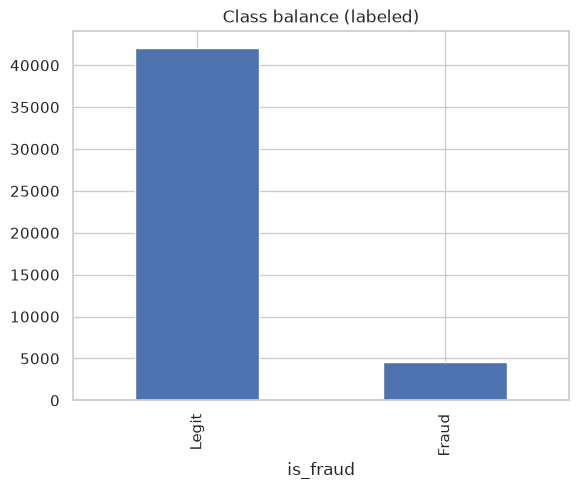

In [3]:
lab = df[df['labeled']==1].copy()
print('labeled:', len(lab))
print(lab['is_fraud'].value_counts())
print('fraud rate: %.4f' % lab['is_fraud'].mean())
lab['is_fraud'].map({0:'Legit',1:'Fraud'}).value_counts().plot(kind='bar', title='Class balance (labeled)')
plt.show()

## 2. Why a temporal split
Fraud patterns evolve over time. A random split leaks future information into training. We split by `time_step`:
- train: t <= 34
- validation: 35..40 (threshold tuning)
- test: t >= 41 (unseen future)

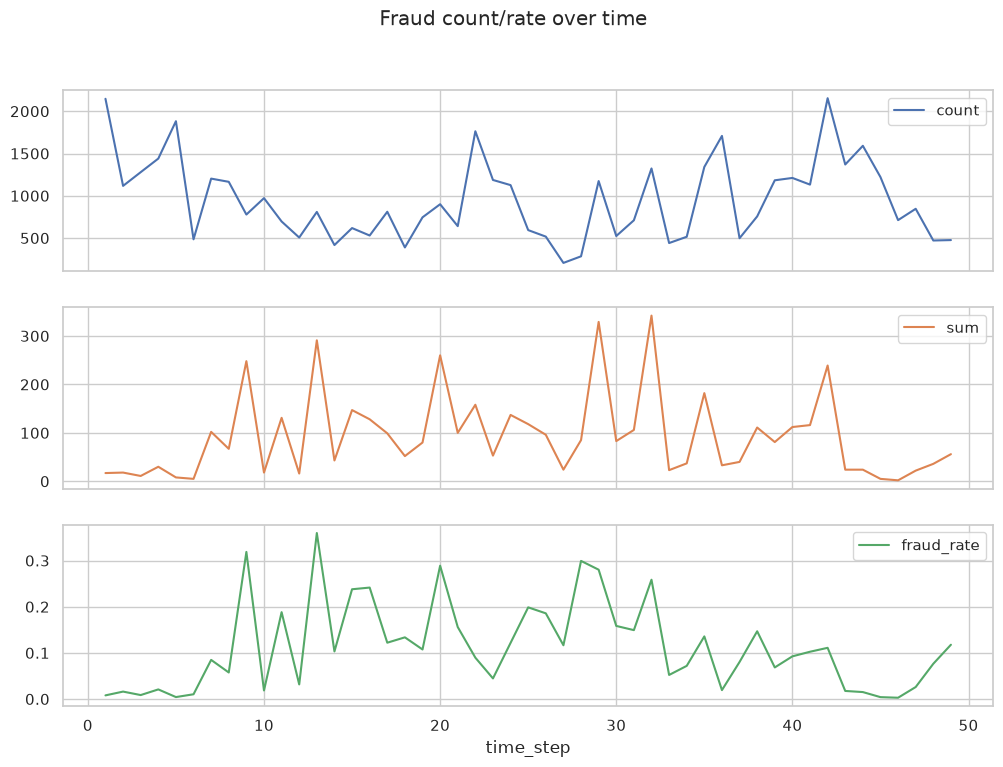

In [4]:
per = lab.groupby('time_step')['is_fraud'].agg(['count','sum','mean'])
per['fraud_rate'] = per['mean']
per[['count','sum','fraud_rate']].plot(subplots=True, figsize=(12,8), title='Fraud count/rate over time')
plt.show()

## 3. Skewness and why log / signed-log transforms
Tree models tolerate skew, but linear models (Logistic Regression) do not. Large monetary-like features (`out_amount`, `in_amount`, `total_degree`) are heavily right-skewed → log1p compression of tails.
For signed features (`net_amount` can be negative), we use a **signed log** (`sign(x)*log1p(|x|)`) so direction is preserved.

Top skewed features:
f_33              113.622163
f_36              112.692074
f_34              102.065339
g_unique_out       96.758312
g_out_degree       96.758312
g_weighted_out     96.758312
f_14               96.434444
f_13               95.018826
f_4                95.014225
f_159              92.119963
f_69               87.010406
f_160              86.509417
f_161              74.700277
f_72               66.004435
f_71               64.380890
dtype: float64


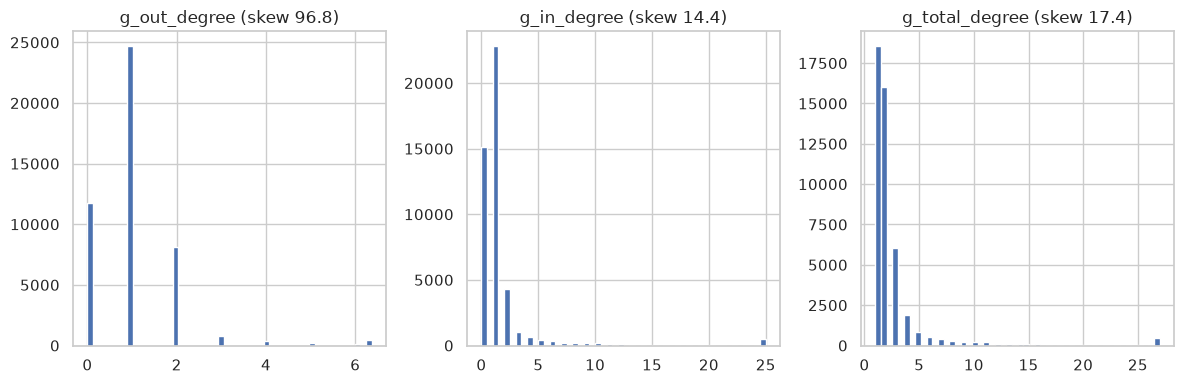

In [5]:
num = lab.select_dtypes(include=[np.number])
skew = num.skew().abs().sort_values(ascending=False)
print('Top skewed features:')
print(skew.head(15))
cols = ['g_out_degree','g_in_degree','g_total_degree','out_amount','in_amount']
cols = [c for c in cols if c in lab.columns]
fig, axes = plt.subplots(1, len(cols), figsize=(4*len(cols),4))
for ax, c in zip(np.atleast_1d(axes), cols):
    ax.hist(lab[c].clip(0, lab[c].quantile(0.99)), bins=50)
    ax.set_title(f'{c} (skew {lab[c].skew():.1f})')
plt.tight_layout(); plt.show()

## 4. Outliers and why robust scaling / winsorization
Feature ranges span many orders of magnitude (e.g., pagerank ~1e-5 vs degree ~1e3). `StandardScaler` uses mean/std and is sensitive to extreme outliers.
- `RobustScaler` uses median/IQR → better for the extreme tails we see below.
- A light **winsorizer** (clip to 0.5/99.5 percentiles) prevents transform blow-ups (we saw an overflow in PowerTransformer without it).

In [6]:
desc = lab[cols].describe(percentiles=[.01,.5,.99]).T
print(desc.to_string())

                  count      mean       std  min   1%  50%    99%    max
g_out_degree    46564.0  1.142471  3.092219  0.0  0.0  1.0   6.37  472.0
g_in_degree     46564.0  1.846985  7.134084  0.0  0.0  1.0  25.00  284.0
g_total_degree  46564.0  2.989455  7.732555  1.0  1.0  2.0  27.00  473.0


## 5. Graph features: do fraud and legit differ?
If fraud and legit nodes have different graph structure (degree, PageRank, community size, mutual links), then graph features are worth engineering — they are features a tabular-only model cannot see.

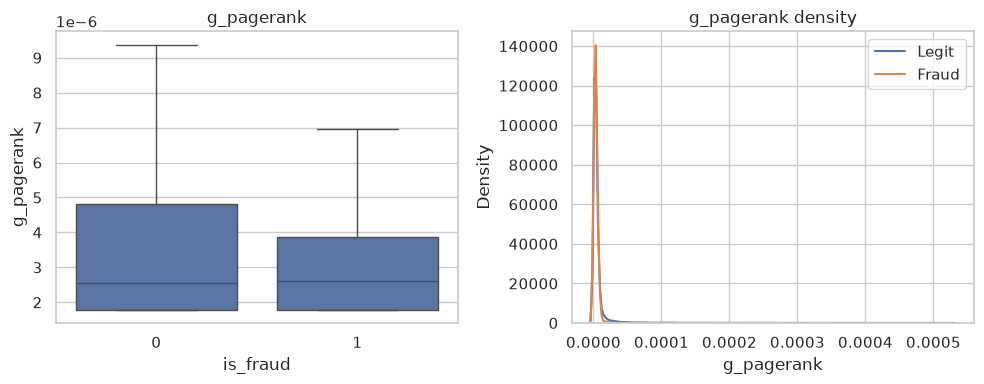

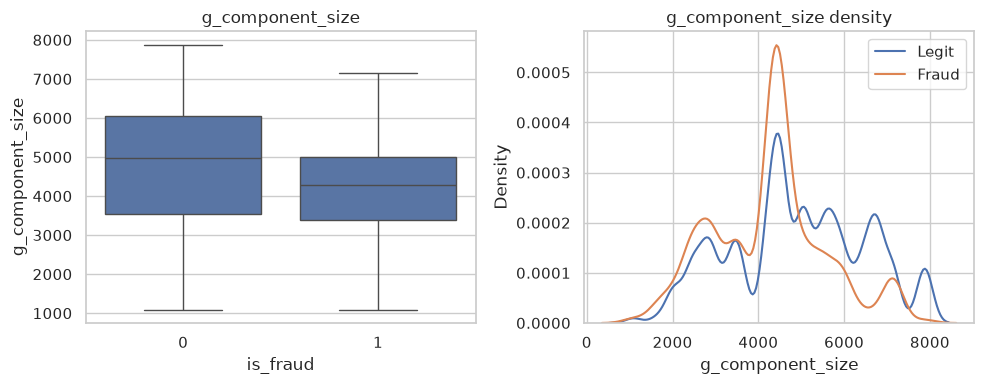

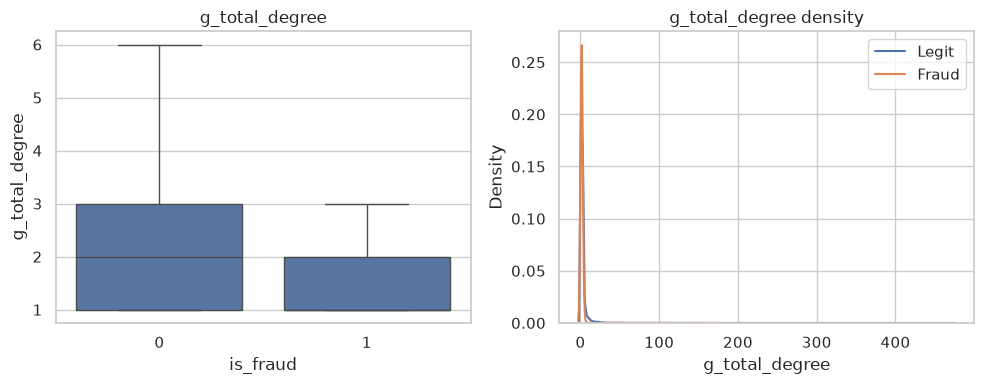

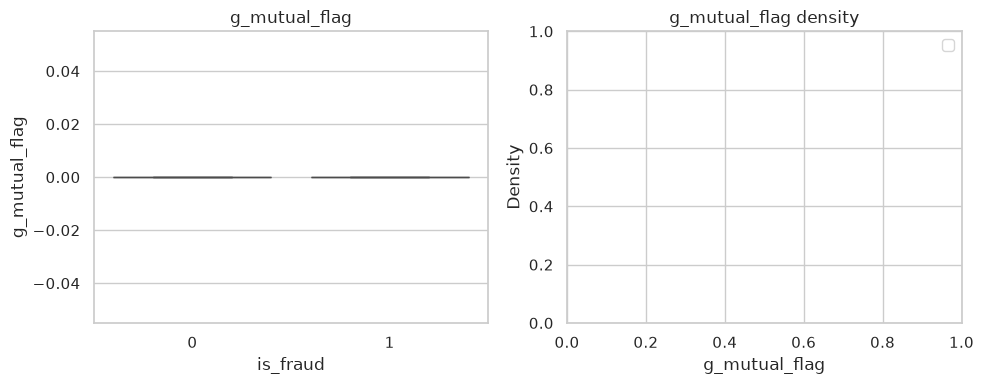

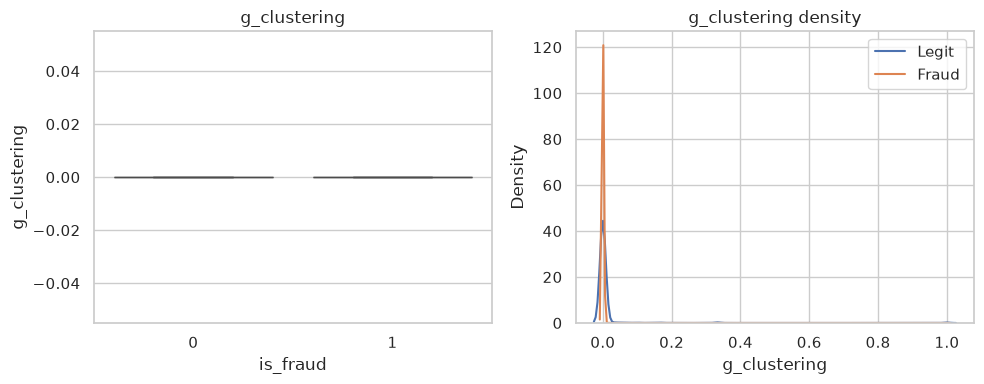

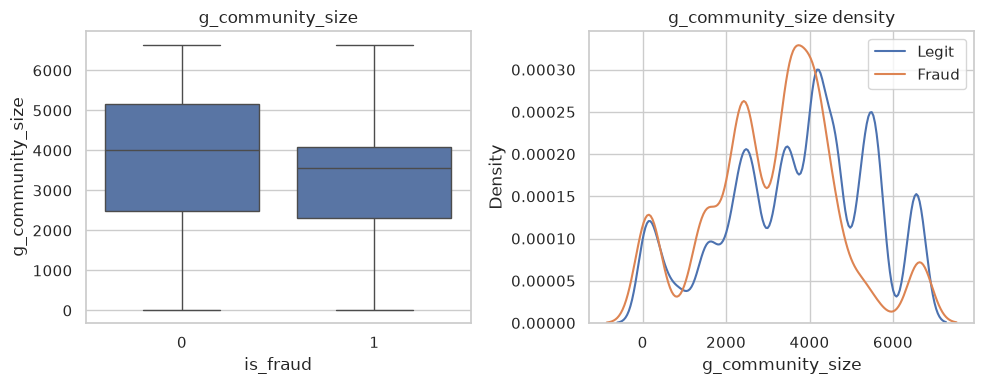

In [7]:
gcols = ['g_pagerank','g_component_size','g_total_degree','g_mutual_flag','g_clustering','g_community_size']
gcols = [c for c in gcols if c in lab.columns]
for c in gcols:
    fig, axes = plt.subplots(1,2, figsize=(10,4))
    sns.boxplot(x='is_fraud', y=c, data=lab, ax=axes[0], showfliers=False)
    axes[0].set_title(c)
    sns.kdeplot(lab[lab['is_fraud']==0][c], label='Legit', ax=axes[1])
    sns.kdeplot(lab[lab['is_fraud']==1][c], label='Fraud', ax=axes[1])
    axes[1].set_title(f'{c} density'); axes[1].legend()
    plt.tight_layout(); plt.show()

In [8]:
# quick numeric summary of graph features by class
print(lab.groupby('is_fraud')[gcols].mean().T.to_string())

is_fraud                    0            1
g_pagerank           0.000006     0.000004
g_component_size  4900.411671  4257.644224
g_total_degree       3.095219     2.011661
g_mutual_flag        0.000000     0.000000
g_clustering         0.008320     0.000356
g_community_size  3704.096242  3126.733113


## 6. Correlation & redundancy
Checking correlations helps detect redundancy and explains why some transforms don't change ranking (tree models are invariant to monotonic transforms; linear models are not).

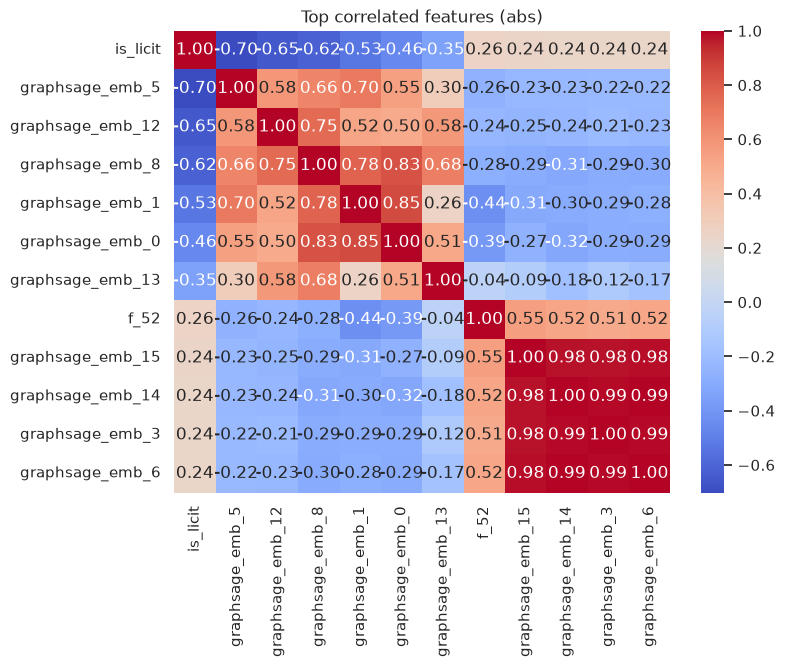

is_licit            1.000000
graphsage_emb_5     0.702738
graphsage_emb_12    0.650313
graphsage_emb_8     0.619603
graphsage_emb_1     0.531992
graphsage_emb_0     0.462495
graphsage_emb_13    0.349670
f_52                0.261472
graphsage_emb_15    0.242051
graphsage_emb_14    0.240080
graphsage_emb_3     0.236030
graphsage_emb_6     0.235513


In [9]:
top = num.corr()['is_fraud'].drop('is_fraud').abs().sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(lab[top.index].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
plt.title('Top correlated features (abs)'); plt.show()
print(top.to_string())

## 7. Missing / infinite values
We impute medians (robust) and clip extremes before transforms so Power/Quantile transforms don't produce inf values.

In [10]:
print('missing total:', int(df.isna().sum().sum()))
inf_counts = {c: int(np.isinf(df[c].replace([np.inf,-np.inf],np.nan)).sum()) for c in df.select_dtypes(include=[np.number]).columns}
print('features with inf:', {k:v for k,v in inf_counts.items() if v>0})

missing total: 0
features with inf: {}


## 8. Preprocessing choices (summary)
| Step | Why |
|---|---|
| Median imputation | robust to outliers, no data leakage (fit on train only) |
| Winsorize 0.5/99.5 | prevents transform overflow, stabilizes linear models |
| Signed log1p | compresses heavy tails, preserves sign for net flows |
| Standard scaler | for roughly symmetric features (log output) |
| Robust scaler | for outlier-heavy raw features |
| Quantile/Power | alternative normalizations tested empirically |
| Class weights | handle 9.8% fraud rate without SMOTE dependency |
| Temporal split | prevents future-leakage, simulates production |
| Cost matrix (FN=$250, FP=$15) | aligns threshold with business value |


In [11]:
# Show the impact of a signed-log + standard scaling on a skewed feature
from sklearn.preprocessing import StandardScaler, RobustScaler
c = 'g_out_degree' if 'g_out_degree' in lab.columns else cols[0]
raw = lab[c].values.reshape(-1,1)
print('raw mean/std:', float(raw.mean()), float(raw.std()))
sl = np.sign(raw)*np.log1p(np.abs(raw))
print('signed-log mean/std:', float(sl.mean()), float(sl.std()))
std = StandardScaler().fit_transform(sl)
print('after standardization mean/std:', float(std.mean()), float(std.std()))

raw mean/std: 1.1424705781290267 3.092185457745338
signed-log mean/std: 0.6342206459860458 0.454397764963111
after standardization mean/std: -1.507637279724635e-16 1.0


## 9. Cost rationale
Fraud is a **cost-sensitive** problem: missing a fraud case (FN) costs far more than a false review (FP).
We choose the decision threshold that minimizes expected cost on the validation set (see `src/evaluation/metrics.py`).

In [12]:
# just a quick illustration of the asymmetry
cost_fn, cost_fp = 250.0, 15.0
y = lab['is_fraud'].values
baseline = y.sum()*cost_fn
print('fraud cases in labeled set:', int(y.sum()))
print('baseline cost if we do nothing: $%.0f' % baseline)
print('one FN costs %.1fx more than one FP' % (cost_fn/cost_fp))

fraud cases in labeled set: 4545
baseline cost if we do nothing: $1136250
one FN costs 16.7x more than one FP


## Takeaways
1. Dataset is **imbalanced** → class weights + PR-AUC + cost-based evaluation.
2. **Temporal** structure is strong → temporal train/val/test split.
3. Feature distributions are **skewed and outlier-heavy** → signed log / robust scaling / winsorization.
4. **Graph features** differ measurably between fraud and legit → they add value beyond raw features.
5. Linear models need transforms; tree models are mostly invariant — we compare both.
6. Business decision threshold is chosen by **cost minimization**, not accuracy.
